# Actividad | Dataset

**Alumno:** César Valladares - A01023506

## Introducción

En esta actividad voy a trabajar con el dataset **Wine Quality**, que tiene información de vinos portugueses "Vinho Verde", tanto tintos como blancos. Son dos archivos: uno con 1,599 vinos tintos y otro con 4,898 vinos blancos. Cada vino tiene 11 variables que vienen de pruebas de laboratorio, como la acidez, el azúcar residual, el pH o el porcentaje de alcohol, y una variable final llamada `quality`, que es la calificación que le dieron expertos en una escala de 0 a 10.

El objetivo de este notebook es entender bien los datos y decidir cómo limpiarlos. Aquí solo hago la exploración; la carga, la limpieza, el entrenamiento del modelo y el registro en MLflow están en el paquete `wine_quality`, y se ejecutan con el script `wine_quality/modeling/train.py`.

El notebook está organizado en estos pasos:

1. Carga y descripción del dataset
2. Análisis exploratorio (EDA)
3. Análisis de limpieza de datos


**Fuente de los datos:** P. Cortez, A. Cerdeira, F. Almeida, T. Matos y J. Reis. *Modeling wine preferences by data mining from physicochemical properties*. Decision Support Systems, Elsevier, 47(4):547 a 553, 2009.


In [1]:
# Librerías base para manejar los datos y hacer gráficas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Paso 1: Carga y descripción del dataset

Cargo los archivos de vinos tintos y blancos y los junto en una sola tabla, agregando una columna `tipo_vino` para saber de cuál viene cada registro. Después reviso su estructura: número de registros, variables, tipos y significado.


In [2]:
# Leer los dos archivos (usan ; como separador)
tinto = pd.read_csv("../data/raw/winequality-red.csv", sep=";")
blanco = pd.read_csv("../data/raw/winequality-white.csv", sep=";")

# Agregar una columna para saber de qué tipo es cada vino
tinto["tipo_vino"] = "tinto"
blanco["tipo_vino"] = "blanco"

# Juntar los dos en una sola tabla
vinos = pd.concat([tinto, blanco], ignore_index=True)

print("Vinos tintos:", tinto.shape)
print("Vinos blancos:", blanco.shape)
print("Total:", vinos.shape)

vinos.head()

Vinos tintos: (1599, 13)
Vinos blancos: (4898, 13)
Total: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo_vino
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,tinto
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,tinto
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,tinto
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto


In [3]:
# Número de registros, variables y tipo de dato de cada columna
print("Registros:", vinos.shape[0])
print("Variables:", vinos.shape[1])
print()
vinos.info()

# Estadísticas de las variables numéricas
estadisticas = vinos.describe().T
estadisticas["mediana"] = vinos.median(numeric_only=True)
estadisticas["moda"] = vinos.mode(numeric_only=True).iloc[0]
estadisticas["rango"] = estadisticas["max"] - estadisticas["min"]

display(estadisticas)

# Conteo de vinos por tipo
display(vinos["tipo_vino"].value_counts())


Registros: 6497
Variables: 13

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  tipo_vino             6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 697.3 KB


,count,mean,std,min,25%,50%,75%,max,mediana,moda,rango
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000,7.00000,6.8000,12.10000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000,0.29000,0.2800,1.50000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000,0.31000,0.3000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000,3.00000,2.0000,65.20000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100,0.04700,0.0440,0.60200
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000,29.00000,29.0000,288.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000,118.00000,111.0000,434.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898,0.99489,0.9972,0.05187
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000,3.21000,3.1600,1.29000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000,0.51000,0.5000,1.78000


tipo_vino
blanco    4898
tinto     1599
Name: count, dtype: int64

### Significado de las variables

El dataset tiene 6,497 registros y 13 variables. Las 11 primeras son resultados de pruebas de laboratorio y son numéricas (`float64`). `quality` es un número entero (`int64`) y `tipo_vino` es texto.

Aunque `quality` está guardada como número entero, en realidad es una variable **categórica ordinal**: cada valor es una calificación y las calificaciones tienen un orden (un 7 es mejor que un 6), pero no es una medición continua como el alcohol o el pH.

| Variable              | Significado                                                       | Unidad        |
|-----------------------|-------------------------------------------------------------------|---------------|
| fixed acidity         | Acidez fija, ácidos que no se evaporan (principalmente tartárico) | g/dm³         |
| volatile acidity      | Acidez volátil (ácido acético); en exceso da sabor a vinagre      | g/dm³         |
| citric acid           | Ácido cítrico, aporta frescura                                    | g/dm³         |
| residual sugar        | Azúcar que queda después de la fermentación                       | g/dm³   |
| chlorides             | Cantidad de sal (cloruro de sodio)                                | g/dm³         |
| free sulfur dioxide   | Dióxido de azufre libre, evita que el vino se eche a perder       | mg/dm³        |
| total sulfur dioxide  | Dióxido de azufre total (libre + combinado)                       | mg/dm³        |
| density               | Densidad del vino, depende del alcohol y el azúcar                | g/cm³         |
| pH                    | Qué tan ácido es el vino (menor valor, más ácido)                 | escala 0 a 14 |
| sulphates             | Sulfatos (sulfato de potasio), ayudan a conservar el vino         | g/dm³         |
| alcohol               | Porcentaje de alcohol                                             | % vol         |
| quality               | **Variable objetivo.** Calificación de expertos                   | 0 a 10        |
| tipo_vino             | Columna que agregué: tinto o blanco                               | texto         |


## Paso 2: Análisis exploratorio (EDA)

Reviso cómo se distribuyen las variables y cómo se relacionan entre ellas y con `quality`, comparando vinos tintos y blancos.


### Distribución de la calidad

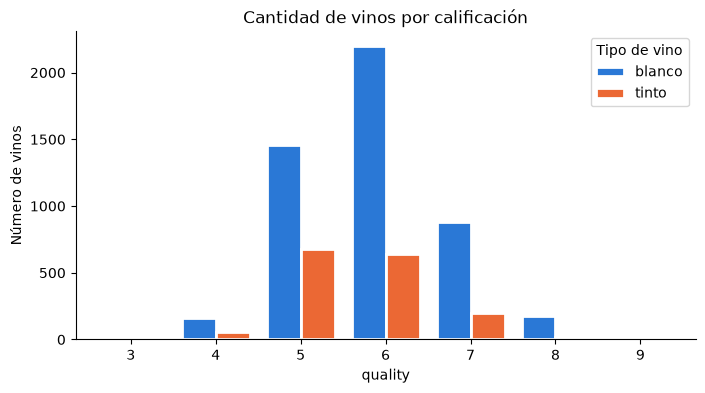

tipo_vino,blanco,tinto
quality,,
3,0.4,0.6
4,3.3,3.3
5,29.7,42.6
6,44.9,39.9
7,18.0,12.4
8,3.6,1.1
9,0.1,0.0


In [4]:
colores = {"blanco": "#2a78d6", "tinto": "#eb6834"}

conteo = vinos.groupby(["quality", "tipo_vino"]).size().unstack(fill_value=0)[["blanco", "tinto"]]

fig, ax = plt.subplots(figsize=(8, 4))
conteo.plot(kind="bar", ax=ax, color=[colores["blanco"], colores["tinto"]], width=0.8, edgecolor="white", linewidth=2)
ax.set_title("Cantidad de vinos por calificación")
ax.set_xlabel("quality")
ax.set_ylabel("Número de vinos")
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Tipo de vino")
plt.show()

# Porcentaje de vinos en cada calificación por tipo
display((conteo / conteo.sum() * 100).round(1))


La mayoría de los vinos tienen calidad 5 o 6: en los blancos suman 74.6 % y en los tintos 82.5 %. Los extremos casi no aparecen; las calificaciones 3, 8 y 9 juntas no llegan al 5 % en ningún tipo, y la calidad 9 solo existe en vinos blancos. En los tintos la calificación más común es 5 y en los blancos es 6, o sea, los blancos tienden a tener calificaciones un poco más altas.

### Comparación entre vinos tintos y blancos

In [5]:
# Media y mediana de cada variable por tipo de vino
vinos.groupby("tipo_vino").agg(["mean", "median"]).T


tipo_vino                        blanco      tinto
fixed acidity        mean      6.854788   8.319637
                     median    6.800000   7.900000
volatile acidity     mean      0.278241   0.527821
                     median    0.260000   0.520000
citric acid          mean      0.334192   0.270976
                     median    0.320000   0.260000
residual sugar       mean      6.391415   2.538806
                     median    5.200000   2.200000
chlorides            mean      0.045772   0.087467
                     median    0.043000   0.079000
free sulfur dioxide  mean     35.308085  15.874922
                     median   34.000000  14.000000
total sulfur dioxide mean    138.360657  46.467792
                     median  134.000000  38.000000
density              mean      0.994027   0.996747
                     median    0.993740   0.996750
pH                   mean      3.188267   3.311113
                     median    3.180000   3.310000
sulphates            mean      0.489847   0.658149
                     median    0.470000   0.620000
alcohol              mean     10.514267  10.422983
                     median   10.400000  10.200000
quality              mean      5.877909   5.636023
                     median    6.000000   6.000000

Los dos tipos de vino son bastante distintos en su composición:

1. Los tintos tienen más acidez fija, casi el doble de acidez volátil y de cloruros, y más sulfatos.
2. Los blancos tienen mucha más azúcar residual (mediana de 5.2 contra 2.2) y casi tres veces más dióxido de azufre total.
3. El alcohol es casi igual en los dos, alrededor de 10.4 %.

Esto me hace pensar que conviene mantener la columna `tipo_vino` como variable para el modelo, porque el mismo valor puede significar algo distinto en un tinto que en un blanco.

### Distribución de las variables

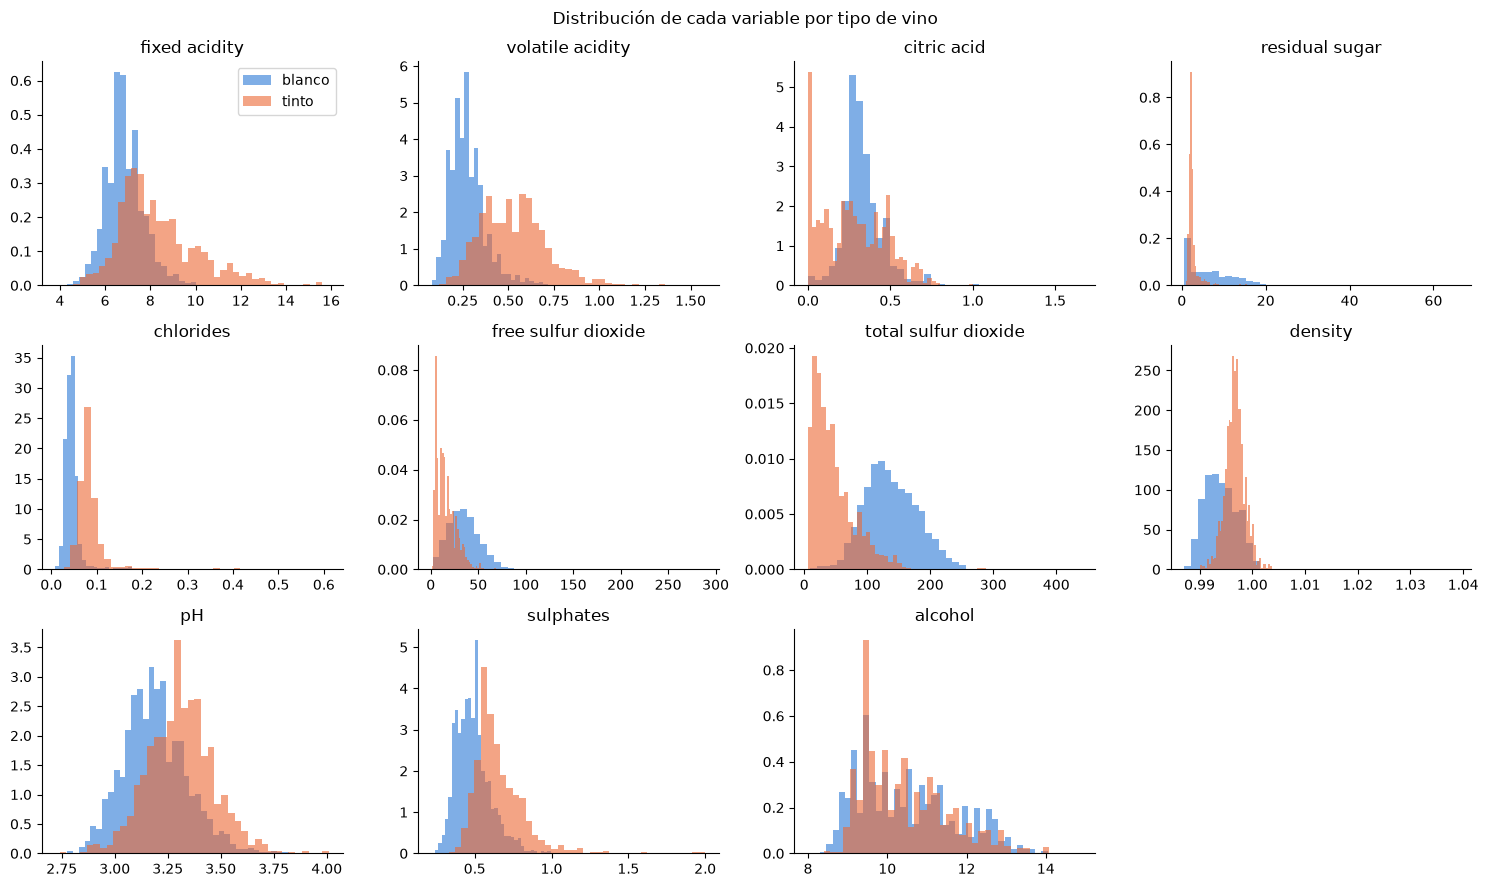

In [6]:
variables = vinos.columns.drop(["quality", "tipo_vino"])

# density=True para comparar la forma aunque haya más vinos blancos que tintos
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.flat, variables):
    for tipo in ["blanco", "tinto"]:
        datos = vinos.loc[vinos["tipo_vino"] == tipo, col]
        ax.hist(datos, bins=40, density=True, alpha=0.6, color=colores[tipo], label=tipo)
    ax.set_title(col)
    ax.spines[["top", "right"]].set_visible(False)
axes.flat[0].legend()
axes.flat[-1].axis("off")
fig.suptitle("Distribución de cada variable por tipo de vino")
plt.tight_layout()
plt.show()


La mayoría de las variables están cargadas hacia la izquierda y tienen una cola larga hacia la derecha. Esto se ve sobre todo en azúcar residual, cloruros, dióxido de azufre libre, sulfatos y densidad, donde hay unos pocos valores muy lejos del resto (por ejemplo azúcar de 65 o dióxido de azufre libre de 289). Esos valores los reviso en el paso 3 para ver si son outliers. El pH es la única variable con una forma parecida a una campana. En dióxido de azufre total y en acidez volátil se ven claramente dos grupos, uno por cada tipo de vino.

### Relación de cada variable con la calidad

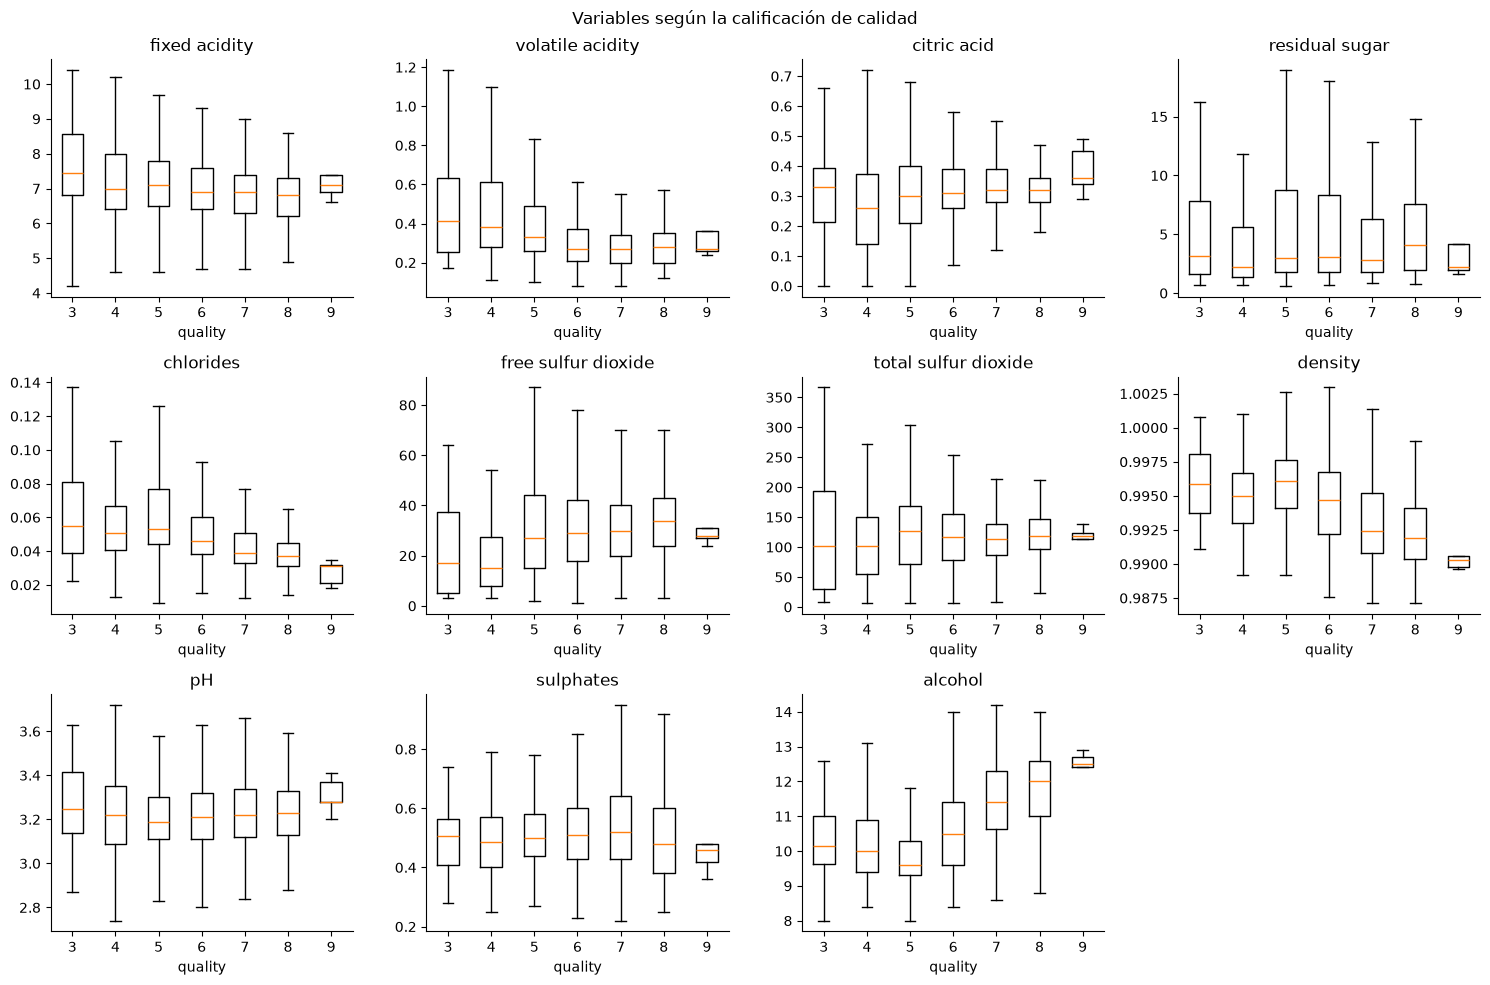

In [7]:
calidades = sorted(vinos["quality"].unique())

# Los outliers se ocultan aquí para ver mejor las medianas; se revisan en el paso 3
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, col in zip(axes.flat, variables):
    grupos = [vinos.loc[vinos["quality"] == q, col] for q in calidades]
    ax.boxplot(grupos, tick_labels=calidades, showfliers=False)
    ax.set_title(col)
    ax.set_xlabel("quality")
    ax.spines[["top", "right"]].set_visible(False)
axes.flat[-1].axis("off")
fig.suptitle("Variables según la calificación de calidad")
plt.tight_layout()
plt.show()


La variable que más cambia con la calidad es el **alcohol**: a partir de la calidad 5, mientras más alcohol, mejor calificación (la mediana pasa de 9.6 en calidad 5 a 12 en calidad 8). La **densidad**, la **acidez volátil** y los **cloruros** hacen lo contrario: bajan cuando la calidad sube. En las demás variables las cajas se ven casi al mismo nivel, así que por sí solas no parecen ayudar mucho a distinguir la calidad. Las cajas de la calidad 9 son muy angostas porque solo hay 5 vinos con esa calificación, así que no se pueden sacar conclusiones de ese grupo.

### Correlaciones

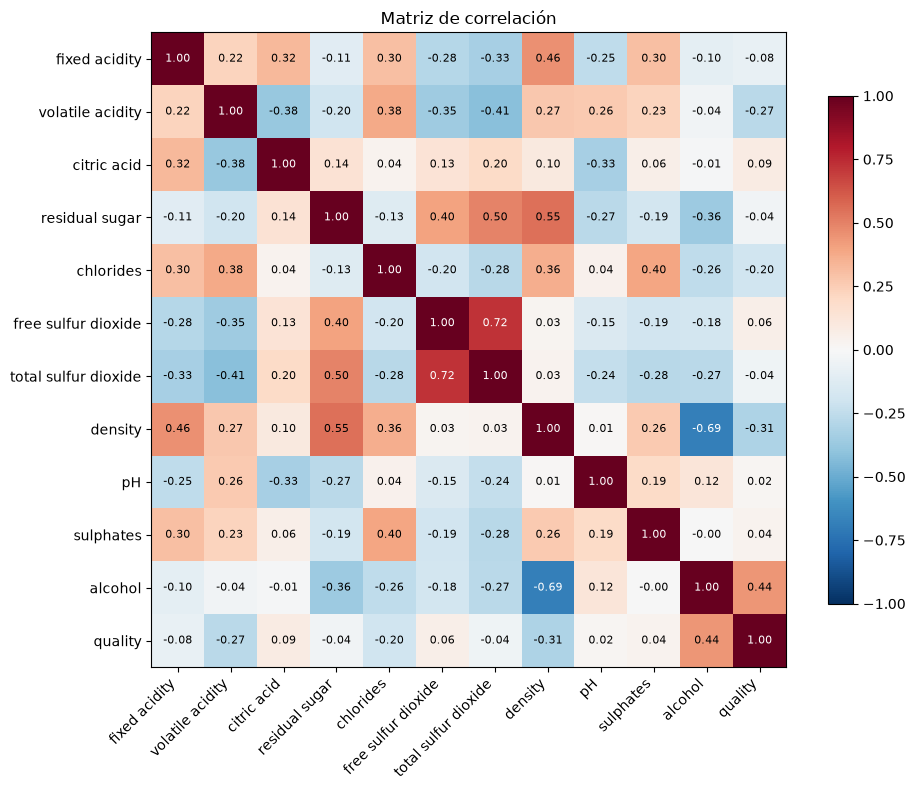

In [8]:
corr = vinos.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        valor = corr.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(valor) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()


En el mapa se ve que algunas variables de entrada están muy relacionadas entre sí:

1. **Dióxido de azufre libre y total (0.72):** tiene sentido, porque el total incluye al libre.
2. **Densidad y alcohol (−0.69):** el alcohol es más ligero que el agua, así que más alcohol baja la densidad.
3. **Densidad y azúcar residual (0.55):** el azúcar hace al vino más denso.
4. **Azúcar residual y dióxido de azufre total (0.50):** las dos son más altas en los vinos blancos.

Estas relaciones explican por qué la densidad tiene una correlación de −0.31 con la calidad: en buena parte refleja el efecto del alcohol. También quiere decir que varias variables repiten información, lo que hay que tomar en cuenta al leer los coeficientes del modelo. Como ninguna correlación pasa de 0.8, para el baseline conservo todas las variables.


In [9]:
# Correlación de cada variable con quality, en general y por tipo de vino
cor_calidad = pd.DataFrame({
    "todos": vinos.corr(numeric_only=True)["quality"],
    "blanco": blanco.corr(numeric_only=True)["quality"],
    "tinto": tinto.corr(numeric_only=True)["quality"],
}).drop("quality")

cor_calidad.sort_values("todos", key=abs, ascending=False)


,todos,blanco,tinto
alcohol,0.444319,0.435575,0.476166
density,-0.305858,-0.307123,-0.174919
volatile acidity,-0.265699,-0.194723,-0.390558
chlorides,-0.200666,-0.209934,-0.128907
citric acid,0.085532,-0.009209,0.226373
fixed acidity,-0.076743,-0.113663,0.124052
free sulfur dioxide,0.055463,0.008158,-0.050656
total sulfur dioxide,-0.041385,-0.174737,-0.185100
sulphates,0.038485,0.053678,0.251397
residual sugar,-0.036980,-0.097577,0.013732


Esto confirma lo que se vio en los boxplots. El alcohol es la variable con la correlación más alta (0.44), seguido de la densidad (−0.31), la acidez volátil (−0.27) y los cloruros (−0.20). Las demás están cerca de cero.

Al separar por tipo aparecen diferencias interesantes:

1. En los tintos, los sulfatos (0.25) y el ácido cítrico (0.23) sí tienen relación con la calidad, pero en los blancos casi nada.
2. La acidez volátil afecta más a los tintos (−0.39) que a los blancos (−0.19).
3. El dióxido de azufre total tiene una correlación de −0.17 en blancos y −0.19 en tintos, pero al juntar los dos tipos baja a −0.04. Esto pasa porque los blancos tienen mucho más dióxido de azufre y a la vez calificaciones un poco más altas, y al mezclarlos se esconde el efecto.

Ninguna correlación es muy fuerte, así que la calidad depende de varias variables juntas y no de una sola. Por eso no espero que un modelo sencillo tenga un error muy bajo.

## Paso 3: Limpieza de datos

In [10]:
# Valores faltantes, tipos de dato y valores negativos
print("Valores faltantes:", vinos.isna().sum().sum())
print("Valores negativos:", (vinos.select_dtypes("number") < 0).sum().sum())
print()
print(vinos.dtypes)

Valores faltantes: 0
Valores negativos: 0

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
tipo_vino                   str
dtype: object


**Decisión:** no hay valores faltantes ni valores negativos, así que no hay nada que corregir aquí. Los tipos de dato también son correctos: las 11 variables de laboratorio son decimales, `quality` es entero y `tipo_vino` es texto.

In [11]:
# Buscar filas repetidas y ver cuántas son de cada tipo de vino
duplicados = vinos.duplicated()
print("Registros duplicados:", duplicados.sum())
print(vinos.loc[duplicados, "tipo_vino"].value_counts())

vinos_limpio = vinos.drop_duplicates().reset_index(drop=True)
print("\nRegistros después de eliminar duplicados:", len(vinos_limpio))
print(vinos_limpio["tipo_vino"].value_counts())

Registros duplicados: 1177
tipo_vino
blanco    937
tinto     240
Name: count, dtype: int64

Registros después de eliminar duplicados: 5320
tipo_vino
blanco    3961
tinto     1359
Name: count, dtype: int64


**Decisión:** elimino los 1,177 registros duplicados (937 blancos y 240 tintos). Si los dejo, al dividir en entrenamiento y prueba un mismo vino podría quedar en los dos conjuntos, y el modelo se evaluaría con datos que ya vio, dando un resultado mejor del real. Quedan 5,320 vinos.

In [12]:
# Outliers con la regla IQR, calculados por separado para cada tipo de vino
def marcar_outliers(df):
    q1 = df[variables].quantile(0.25)
    q3 = df[variables].quantile(0.75)
    iqr = q3 - q1
    return (df[variables] < q1 - 1.5 * iqr) | (df[variables] > q3 + 1.5 * iqr)

outliers = pd.concat([
    marcar_outliers(vinos_limpio[vinos_limpio["tipo_vino"] == tipo]) for tipo in ["tinto", "blanco"]
]).loc[vinos_limpio.index]

display(outliers.sum().sort_values(ascending=False).to_frame("outliers"))

filas_con_outlier = outliers.any(axis=1)
print("Filas con al menos un outlier:", filas_con_outlier.sum(), "de", len(vinos_limpio))

# En qué calidades están esos vinos
resumen = pd.DataFrame({
    "total": vinos_limpio["quality"].value_counts(),
    "con outlier": vinos_limpio.loc[filas_con_outlier, "quality"].value_counts(),
}).sort_index()
resumen["% con outlier"] = (resumen["con outlier"] / resumen["total"] * 100).round(1)
resumen


,outliers
chlorides,265
citric acid,224
volatile acidity,152
sulphates,151
fixed acidity,147
residual sugar,142
pH,74
free sulfur dioxide,70
total sulfur dioxide,59
density,41


Filas con al menos un outlier: 1046 de 5320


,total,con outlier,% con outlier
quality,,,
3,30,18,60.0
4,206,89,43.2
5,1752,424,24.2
6,2323,373,16.1
7,856,115,13.4
8,148,26,17.6
9,5,1,20.0


In [13]:
# Los valores más altos de azúcar residual y densidad
display(vinos_limpio.nlargest(3, "residual sugar"))
display(vinos_limpio.nlargest(3, "density"))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo_vino
3653,7.8,0.965,0.60,65.80,0.074,8.0,160.0,1.03898,3.39,0.69,11.7,6,blanco
2753,7.9,0.330,0.28,31.60,0.053,35.0,176.0,1.01030,3.15,0.38,8.8,6,blanco
4314,6.8,0.450,0.28,26.05,0.031,27.0,122.0,1.00295,3.06,0.42,10.6,6,blanco


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo_vino
3653,7.8,0.965,0.60,65.8,0.074,8.0,160.0,1.03898,3.39,0.69,11.7,6,blanco
2753,7.9,0.330,0.28,31.6,0.053,35.0,176.0,1.01030,3.15,0.38,8.8,6,blanco
1216,10.2,0.540,0.37,15.4,0.214,55.0,95.0,1.00369,3.18,0.77,9.0,6,tinto


**Decisión:** no elimino todos los outliers. Son 1,046 filas, casi el 20 % de los datos, y en su mayoría son valores posibles en un vino. Además, muchos están en las calidades que menos datos tienen: el 60 % de los vinos con calidad 3 tiene algún outlier. Si los quito, el modelo tendría todavía menos ejemplos de vinos malos y buenos.

Solo elimino un vino blanco que tiene 65.8 de azúcar residual, más del doble que el siguiente (31.6), y una densidad de 1.039, cuando el siguiente valor más alto es 1.010. Está muy separado del resto en dos variables a la vez, así que puede ser un error de captura o un vino muy distinto a los demás.

In [16]:
# La limpieza final se aplica con la misma función que usa el script de entrenamiento
from wine_quality.dataset import limpiar_datos

vinos_limpio = limpiar_datos(vinos)
print("Registros después de la limpieza:", len(vinos_limpio))
vinos_limpio[["tipo_vino", "es_tinto"]].value_counts()


Registros después de la limpieza: 5319


tipo_vino  es_tinto
blanco     0           3960
tinto      1           1359
Name: count, dtype: int64

**Decisión:** el modelo solo acepta números, así que creo la columna `es_tinto` (1 si es tinto y 0 si es blanco). Dejo `tipo_vino` en la tabla solo como referencia; no entra al modelo.

### Resumen de la limpieza

| Problema          | Resultado   | Decisión                                    |
|-------------------|-------------|---------------------------------------------|
| Valores faltantes | 0           | Ninguna acción                              |
| Tipos de dato     | Correctos   | Crear `es_tinto` como número                |
| Duplicados        | 1,177       | Eliminarlos                                 |
| Outliers (IQR)    | 1,046 filas | Conservarlos, solo quitar 1 valor extremo   |

Al final quedan **5,319 vinos** para entrenar y evaluar el modelo.
